# 02 · Oversight checks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/fintech-brokerage/aml-monitoring-oversight/notebooks/02_oversight_checks.ipynb)

The checks an AML oversight team runs, one per question: did the monitoring get all the data, do the rules still work as approved, do they cover the risks, are the decisions right, are cases handled in time, are clients screened, are reviews up to date. Each result here ends up as a KRI or a finding in notebook 03.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "fintech-brokerage/aml-monitoring-oversight"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "aml_oversight").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: aml-monitoring-oversight


In [2]:
from aml_oversight import config as C, pipeline, oversight as O, reporting, db

tables = pipeline.load_tables()      # reads data/, or generates it if missing
run = pipeline.run(tables)
print(f"{len(tables['clients']):,} clients, {len(tables['transactions']):,} transactions, "
      f"{len(tables['alerts']):,} alerts, {len(tables['screening_hits']):,} screening hits")

15,000 clients, 327,703 transactions, 1,919 alerts, 1,228 screening hits


## 1. Did monitoring receive every transaction?

Reconcile the core ledger with the monitoring feed by month and source. This is the first check because every other one assumes it passes.

,month,source,ledger_count,feed_count,ledger_eur,missing_count,missing_eur
25,2026-06,CARD PSP-B,1219,412,537790.24,807,352559.91
28,2026-07,CARD PSP-B,1179,970,533107.98,209,90627.93


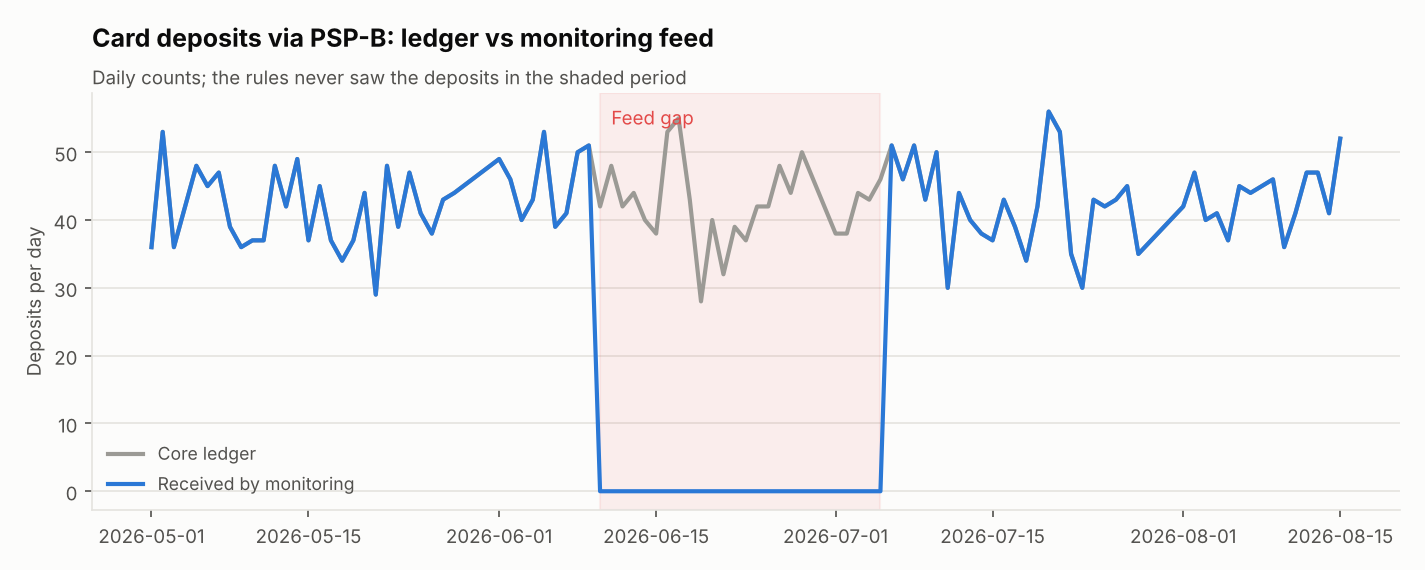

In [3]:
display(run.completeness[run.completeness["missing_count"] > 0])
display(Image(filename=str(reporting.plot_feed_gap(tables["transactions"], tables["tm_feed_ids"], Path("outputs/figures/feed_gap.png")))))

For almost four weeks, card deposits through one payment provider never reached the rules. Nobody in the first line noticed, because a missing transaction does not raise an alert.

## 2. Do the rules still work as approved?

Alert volumes per rule should only move for a reason. R02 dropped sharply in April.

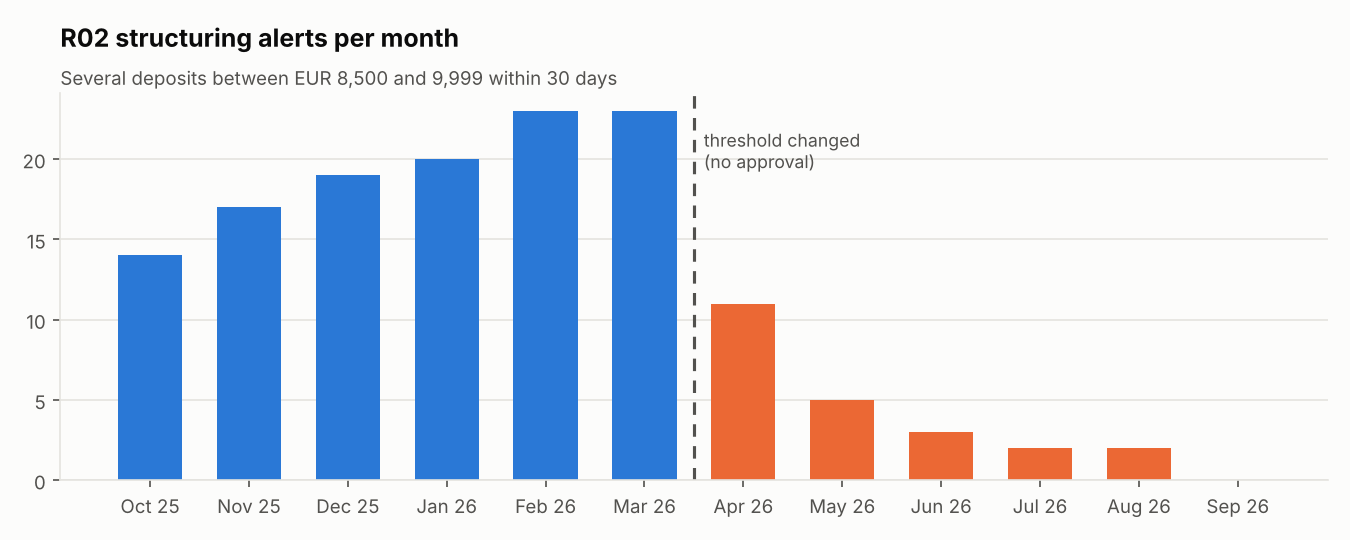

{'rule': 'R02', 'rate_before': np.float64(19.333333333333332), 'rate_after': np.float64(3.8333333333333335), 'change_pct': np.float64(-0.8017241379310345), 'p_value': 3.9040348640344726e-16}

In [4]:
display(Image(filename=str(reporting.plot_rule_volume(tables["alerts"], "R02", Path("outputs/figures/r02_volume.png")))))
run.volume_change

The vendor raised the R02 deposit count from 3 to 5 without a change request. A below-the-line test re-runs the rule on the period since April at lower counts:

In [5]:
run.below_the_line

,min_deposits,clients_alerted,structuring_clients,other_clients
0,3,71,14,57
1,4,21,10,11
2,5,11,7,4


At the approved setting of 3, the rule would have alerted on twice as many structuring clients since April. It would also bring more false positives, which may be why someone changed it, but that trade-off has to be decided and documented, not made quietly in a vendor console.

## 3. Do the rules cover the risks?

,rule,description,alerts,escalated,sars,escalation_rate,sar_conversion
0,R01,"Single deposit of EUR 15,000 or more",426,130,103,0.305,0.242
1,R02,"Several deposits between EUR 8,500 and 9,999 within 30 days",139,61,54,0.439,0.388
2,R03,"Rapid in and out: 80% of deposits withdrawn within 7 days, little trading",80,67,61,0.838,0.762
3,R04,Funding from 2 or more third-party accounts within 30 days,496,156,120,0.315,0.242
4,R05,Deposit from a high-risk jurisdiction,94,50,45,0.532,0.479
5,R06,"Monthly deposits above 5x the expected amount and above EUR 20,000",642,228,193,0.355,0.301


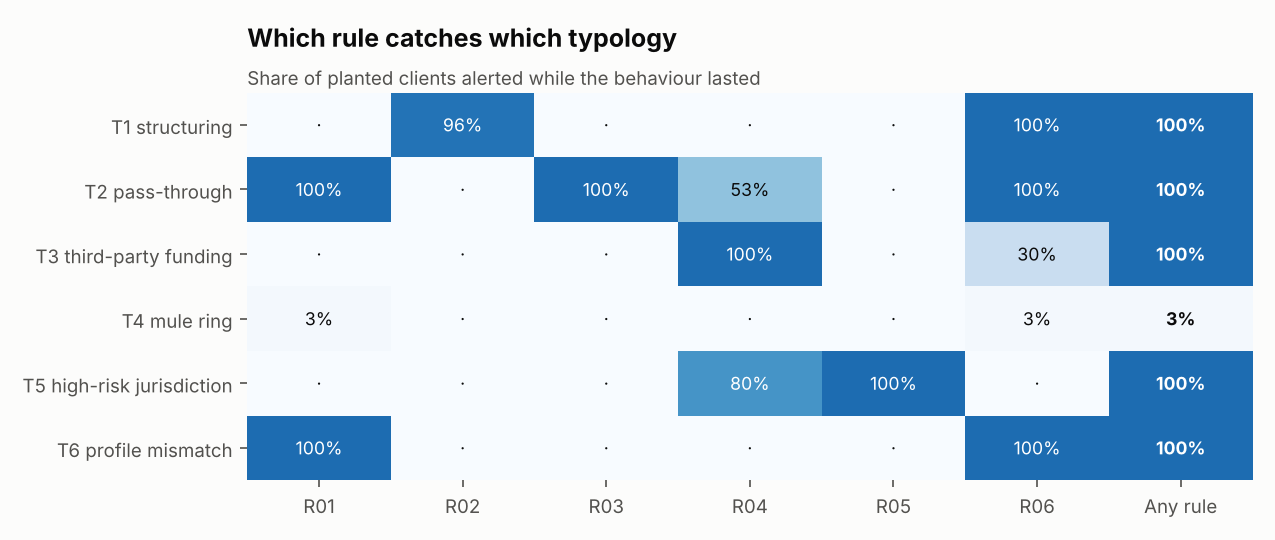

In [6]:
display(run.rules)
display(Image(filename=str(reporting.plot_coverage(run.coverage, Path("outputs/figures/typology_coverage.png")))))

Five typologies are covered, most by two rules. Mule rings are not: their money looks like the client's own and gets traded before it leaves. What gives them away is shared infrastructure, so the next check looks for clients linked by a payout account or a device.

,network_id,clients,shared_payout,shared_device,deposits,deposits_eur,withdrawn_eur
0,N001,6,True,True,162,113978.46,95992.04
1,N002,6,True,False,190,146350.22,131512.60
2,N003,6,True,True,167,111812.23,94821.11
3,N004,6,True,False,185,137341.77,123196.21
4,N005,6,True,True,177,154108.46,101157.35
5,N006,6,True,False,164,204053.00,100407.43


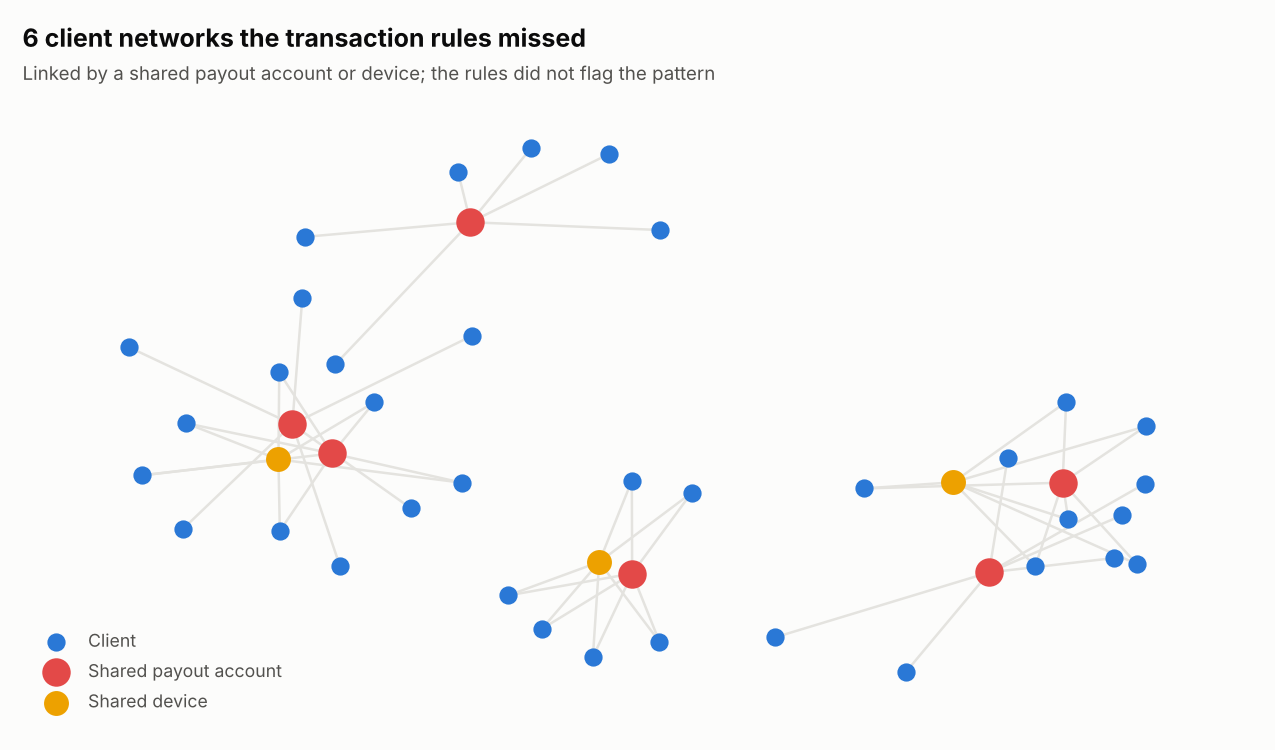

,payout_account,clients,client_ids
0,IBAN13c0e8c116e4,6,"C002167, C005210, C006322, C006531, C008455, C010753"
1,IBAN42a3106aa4f9,6,"C000093, C000706, C008072, C008632, C010310, C012456"
2,IBAN5e478f8eaa71,6,"C001026, C002170, C004923, C006321, C008508, C013558"
3,IBAN8e1310234115,6,"C002241, C007936, C009026, C013257, C013580, C014173"
4,IBANc8ef3626f643,6,"C000983, C001562, C008282, C013006, C013519, C014818"


In [7]:
display(run.networks.drop(columns="client_ids"))
display(Image(filename=str(reporting.plot_networks(tables["clients"], run.networks, Path("outputs/figures/mule_networks.png")))))
display(db.run_sql(db.connect(tables), "04_shared_payout_accounts.sql").head())

## 4. Are the decisions right?

Each quarter, a random sample of alerts closed with no concern is re-reviewed. With 59 cases and no errors, you can say with 95% confidence that the error rate is below 5%. The sample is spread across analysts so that each one gets looked at. Error rates come with Clopper-Pearson intervals, because 30 cases per analyst is not much.

Sample size per quarter: 59


,analyst,error_type,sampled,errors,error_rate,ci_low,ci_high
0,A01,decision_error,26,1,0.0385,0.0010,0.1964
2,A02,decision_error,29,1,0.0345,0.0009,0.1776
4,A03,decision_error,28,0,0.0000,0.0000,0.1234
6,A04,decision_error,31,0,0.0000,0.0000,0.1122
8,A05,decision_error,28,1,0.0357,0.0009,0.1835
10,A06,decision_error,36,8,0.2222,0.1012,0.3915
12,A07,decision_error,26,1,0.0385,0.0010,0.1964
14,A08,decision_error,33,0,0.0000,0.0000,0.1058


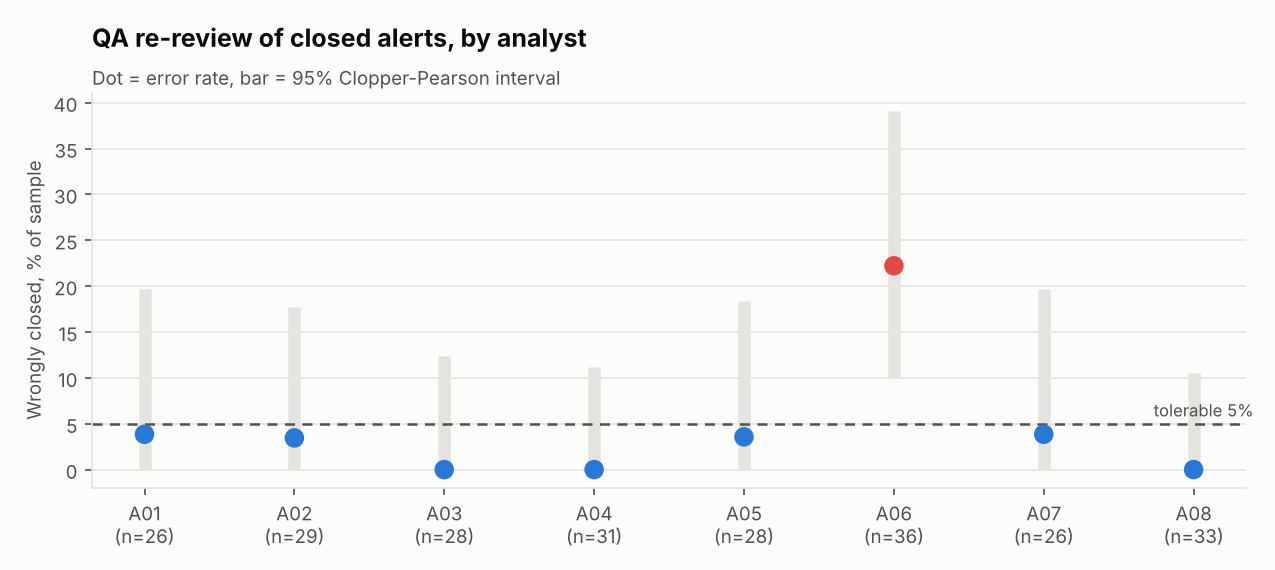

In [8]:
print("Sample size per quarter:", O.zero_failure_sample_size())
display(run.qa_by_analyst.query("error_type == 'decision_error'"))
display(Image(filename=str(reporting.plot_qa(run.qa_by_analyst, Path("outputs/figures/qa_by_analyst.png")))))

Analyst A06 is the only one whose whole interval sits above the tolerable 5%. That justifies a full lookback of the analyst's closures:

In [9]:
print(len(run.lookback), "cases A06 closed that should have been escalated")
run.lookback.head()

46 cases A06 closed that should have been escalated


,alert_id,client_id,rule,alert_date,l1_rationale
45,AL000046,C011182,R06,2025-10-16,Activity consistent with declared income and trading history.
101,AL000102,C007455,R01,2025-10-26,One-off transfer explained by client (property sale); documents on file.
183,AL000184,C003606,R01,2025-11-15,Third-party deposit from spouse's account; relationship verified.
292,AL000293,C007339,R05,2025-12-02,One-off transfer explained by client (property sale); documents on file.
311,AL000312,C004289,R06,2025-12-07,Deposits match recurring savings pattern seen over 12 months.


## 5. Timeliness, documentation, screening, reviews

In [10]:
display(run.kpis[["month", "alerts_created", "backlog_month_end", "backlog_over_sla", "closed_over_sla_pct", "missing_rationale_pct", "sars_filed", "median_days_alert_to_sar"]])
print(run.screening)
display(run.screening_qa[["client_id", "entry_id", "match_score", "birth_year_match", "decision", "reviewer_finding"]])
display(run.reviews)

{'hits': 1228, 'true_matches_confirmed': 59, 'false_positive_rate': 0.9519543973941368, 'new_clients_screened': 3161, 'screened_late': 62, 'late_window': '2026-03-09 to 2026-03-13'}


,month,alerts_created,backlog_month_end,backlog_over_sla,closed_over_sla_pct,missing_rationale_pct,sars_filed,median_days_alert_to_sar
0,2025-10,120,30,0,0.0000,0.0222,2,14.5
1,2025-11,163,32,0,0.0062,0.0373,15,19.0
2,2025-12,179,31,0,0.0000,0.0278,44,22.0
3,2026-01,206,36,0,0.0050,0.0348,69,22.0
4,2026-02,201,49,0,0.0000,0.0372,72,20.0
5,2026-03,174,30,0,0.0052,0.0415,93,20.0
6,2026-04,197,41,0,0.0161,0.0430,71,21.0
7,2026-05,184,38,0,0.0160,0.0535,92,22.0
8,2026-06,157,45,0,0.0067,0.0600,59,22.0
9,2026-07,131,71,1,0.0000,0.0381,37,22.0


,client_id,entry_id,match_score,birth_year_match,decision,reviewer_finding
29,C002880,W0151,0.933,True,false positive,Closed correctly
512,C007987,W0902,0.929,True,false positive,"Wrongly closed: same person, spelling variant"
588,C008218,W0204,0.909,True,false positive,Closed correctly
741,C006618,W0032,0.929,True,false positive,Closed correctly
870,C006736,W0162,0.923,True,false positive,Closed correctly
979,C010559,W0155,0.923,True,false positive,Closed correctly
1023,C001416,W0177,1.000,True,false positive,Closed correctly
1189,C000606,W0193,0.929,True,false positive,Closed correctly


,risk_rating,clients,overdue
0,high,551,43
1,low,12030,138
2,medium,2419,51


One sanctions hit with a matching year of birth and a name score of 0.93 was closed as a false positive. The reviewer judges it to be the same person with a spelling variant. That is the most serious finding of the year.